In [2]:
import time
import random
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12})
import numpy as np
from scipy.stats import gaussian_kde

from matplotlib.colors import LinearSegmentedColormap

In [ ]:
start = time.time()
nums = int(1e3)

xmin = 1  # avoid log(0)
xmax = 1e4
jmax = 1

# Generate x values uniformly in log scale
log_xmin = np.log10(xmin)
log_xmax = np.log10(xmax)
xlist = 10 ** np.random.uniform(log_xmin, log_xmax, nums)

# Generate j values with the given constraints
jlist = [random.uniform(np.sqrt(2 * (x / xmax) - (x / xmax) ** 2), jmax) for x in xlist]

data = {"xvalue": xlist, "jvalue": jlist}
df = pd.DataFrame(data)
df.to_csv("data/runtime/copy_data_0.csv", index=False)
end = time.time()

In [ ]:
# generate the initial data "data/runtime/copy_data_0.csv"--powerlaw index
nums = int(1e3)
u = np.random.rand(nums)
xlist = (1e6 * u) ** (2 / 3)
jlist = [random.uniform(np.sqrt(2 * (x / xmax) - (x / xmax) ** 2), jmax) for x in xlist]
data = {"xvalue": xlist, "jvalue": jlist}
df = pd.DataFrame(data)
df.to_csv("data/runtime/copy_data_0.csv", index=False)

In [ ]:
# check the initial data
df = pd.read_csv("data/runtime/copy_data_0.csv")
xlist = df["xvalue"].values
jlist = df["jvalue"].values

kde_x = gaussian_kde(xlist)
kde_j = gaussian_kde(jlist)


def dis_x(x):
    return kde_x(x)


def dis_j(j):
    return kde_j(j)


plt.figure(figsize=(12, 10))
jmin = 0
jmax = 1
xmin = 1e0
xmax = 1e4
x1 = np.linspace(jmin, jmax, int(1e4))
y1 = [dis_j(_) for _ in x1]
x2 = np.linspace(xmin, xmax, int(1e4))
y2 = [dis_x(_) for _ in x2]
plt.subplot(2, 1, 1)
plt.semilogy(x1, y1)
plt.xlabel("j")
plt.ylabel("pdf")
plt.grid(True, which="both", ls="--")

plt.subplot(2, 1, 2)
plt.loglog(x2, y2)
plt.xlabel("x")
plt.ylabel("pdf")
plt.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()

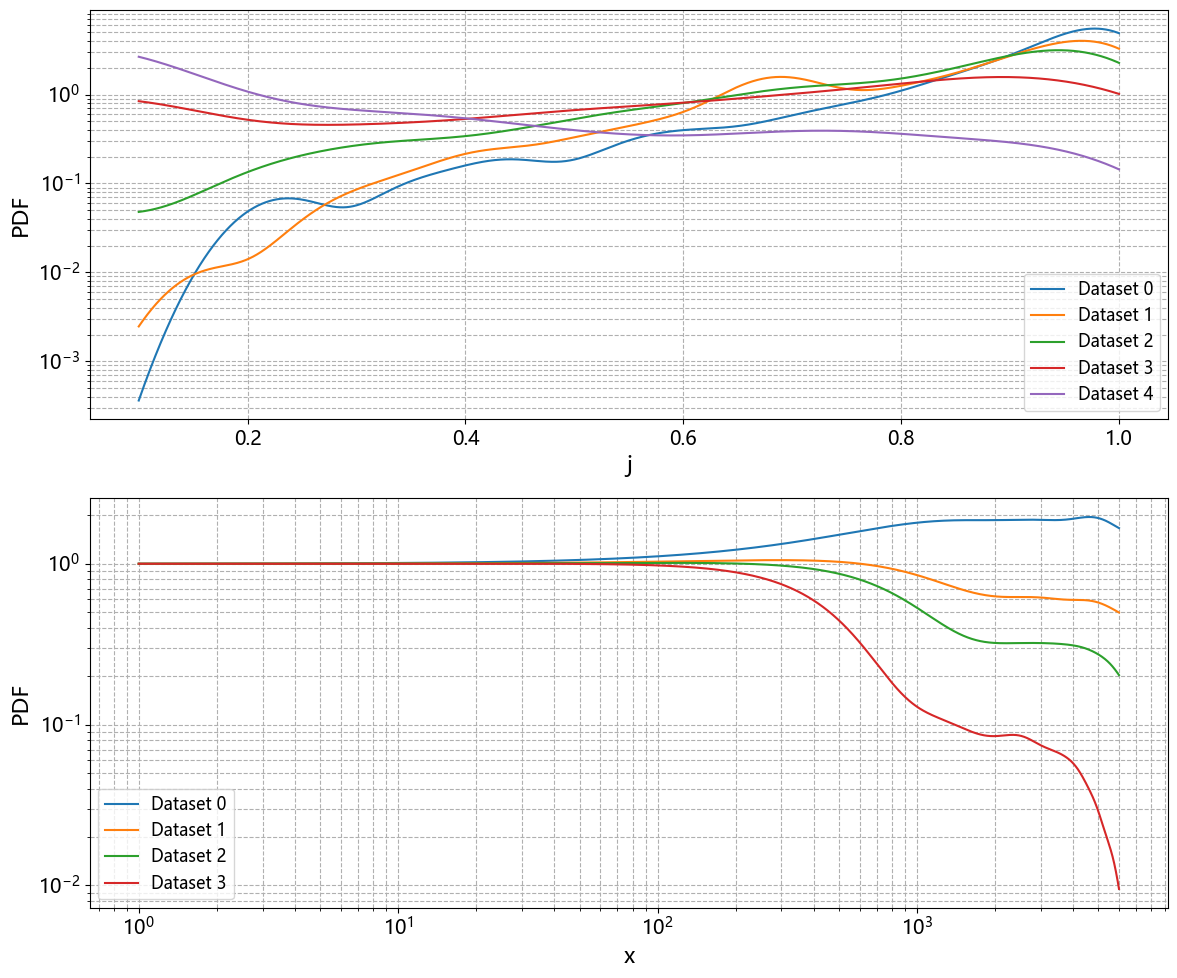

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import os

# distibution function evolution plot
plt.rcParams.update({"font.size": 14})

all_x = []
all_j = []

# get all CSV files
for i in range(5):
    df = pd.read_csv(f"data/snapshots/archived/annihilation/copy_data_{i}.csv")
    all_x.extend(df["xvalue"].values)
    all_j.extend(df["jvalue"].values)

kde_x = gaussian_kde(all_x)
kde_j = gaussian_kde(all_j)

jmin, jmax = 0.1, 1
xmin, xmax = 1, 6e3

plt.figure(figsize=(12, 10))

# subplot of j distribution
plt.subplot(2, 1, 1)
for i in range(5):
    df = pd.read_csv(f"data/snapshots/archived/annihilation/copy_data_{i}.csv")
    j_values = df["jvalue"].values
    kde = gaussian_kde(j_values)
    x1 = np.linspace(jmin, jmax, int(1e4))
    y1 = kde(x1)
    plt.semilogy(x1, y1, label=f"Dataset {i}")  # 纵轴对数

plt.xlabel("j", fontsize=16)
plt.ylabel("PDF", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="--")

# subplot of x distribution
plt.subplot(2, 1, 2)
for i in range(4):
    df = pd.read_csv(f"data/snapshots/archived/annihilation/copy_data_{i}.csv")
    x_values = df["xvalue"].values
    kde = gaussian_kde(x_values)
    x2 = np.logspace(np.log10(xmin), np.log10(xmax), int(1e4))
    y2 = kde(x2)
    y2 = y2 / kde(0)
    plt.loglog(x2, y2, label=f"Dataset {i}")  # 双对数

plt.xlabel("x", fontsize=16)
plt.ylabel("PDF", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="--")

plt.tight_layout()

# filepath = os.path.join(os.path.expanduser("~"),"Desktop","evoltion1.png")
# plt.savefig(filepath)
plt.show()

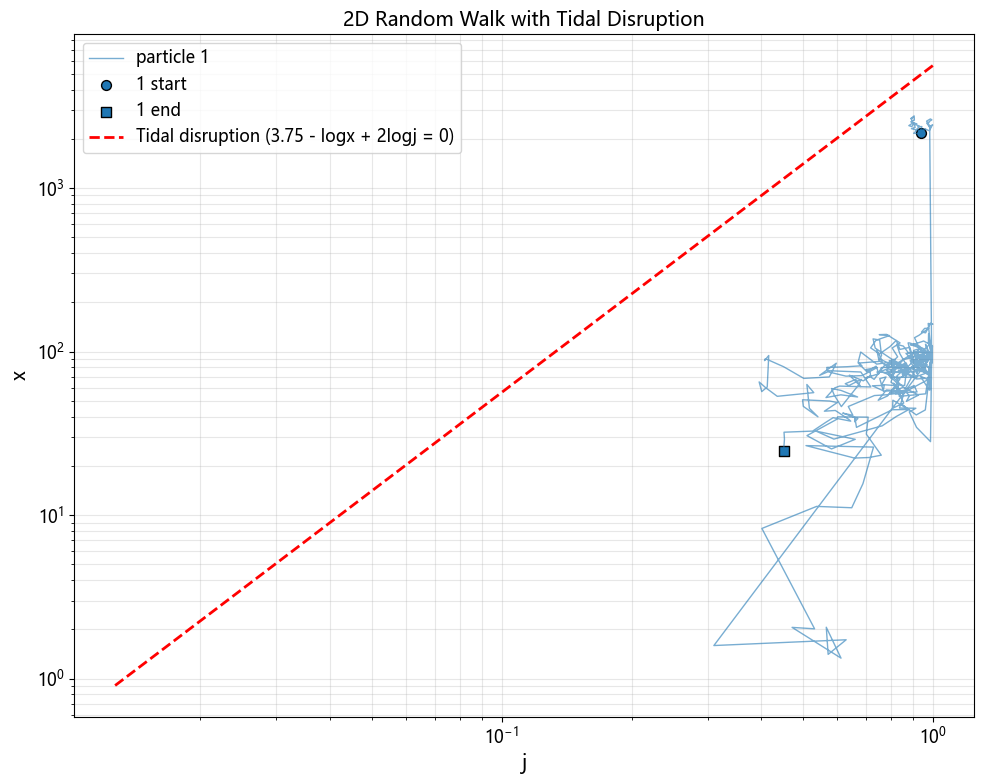

In [7]:
# plot random walk trajectory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]  # 或其他支持中文的字体
plt.rcParams["axes.unicode_minus"] = False  # 用于正常显示负号

# Load data
y_data = pd.read_csv("data/snapshots/new_annihilation/energytrack.csv")
x_data = pd.read_csv("data/snapshots/new_annihilation/angulertrack.csv")

num_particles = x_data.shape[1]  # Assuming first column is index/time
num_steps = x_data.shape[0]

colors = list(mcolors.TABLEAU_COLORS.values())[:num_particles]  # 使用前三个Tableau颜色

plt.figure(figsize=(10, 8))

for i in range(1):  

    # ind_1 = [500,150,500,500]  # Adjusted for 4 particles, each with 100 steps
    ind_1 = 500
    x = x_data.iloc[range(ind_1), i]  
    y = y_data.iloc[range(ind_1), i]
    
    plt.loglog(x, y, color=colors[i], alpha=0.6, linewidth=1, label=f"particle {i+1}")
    
    # Plot start and end points
    if len(x) > 0:
        plt.scatter(
            x.iloc[0],
            y.iloc[0],
            color=colors[i],
            s=50,
            marker="o",
            edgecolor="black",
            label=f"{i+1} start",
        )
        plt.scatter(
            x.iloc[-1],
            y.iloc[-1],
            color=colors[i],
            s=50,
            marker="s",
            edgecolor="black",
            label=f"{i+1} end",
        )

# 添加潮汐瓦解曲线 (3.75 - logx + 2logj = 0 → x = 10^4 * j^2)
if num_particles > 0:
    x_min = x_data.iloc[:, 1:].min().min()
    x_max = x_data.iloc[:, 1:].max().max()
    j_values = np.logspace(np.log10(max(x_min, 1e-10)), np.log10(x_max), 100)  # Avoid log(0)
    x_tidal = 10**3.75 * j_values**2
    plt.loglog(j_values, x_tidal, 'r--', linewidth=2, label="Tidal disruption (3.75 - logx + 2logj = 0)")

# 优化图例处理 - 避免重复
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc="best")

plt.title("2D Random Walk with Tidal Disruption", fontsize=14)
plt.xlabel("j", fontsize=14)
plt.ylabel("x", fontsize=14)
plt.grid(True, which="both", alpha=0.3)

# 自动调整布局
plt.tight_layout()

plt.show()

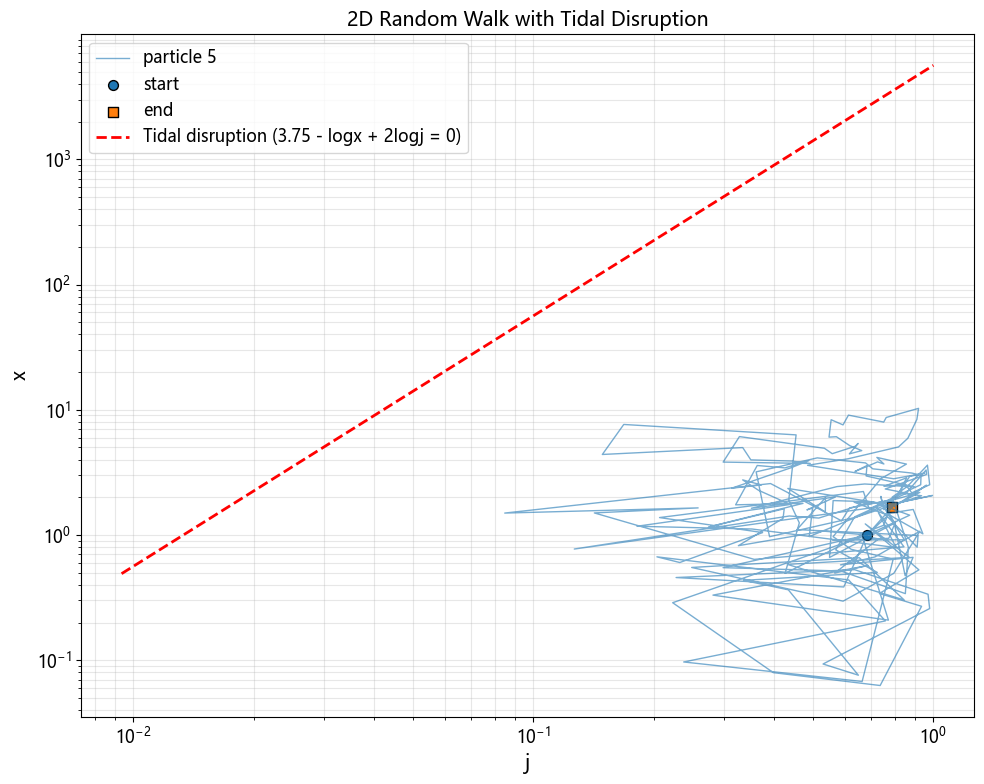

In [6]:
# plot random walk trajectory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]  # 或其他支持中文的字体
plt.rcParams["axes.unicode_minus"] = False  # 用于正常显示负号

# Load data
y_data = pd.read_csv("data/snapshots/archived/annihilation/energytrack.csv")
x_data = pd.read_csv("data/snapshots/archived/annihilation/angulertrack.csv")

x=x_data.iloc[range(1,244),2]
y=y_data.iloc[range(1,244),2]
plt.figure(figsize=(10, 8))
plt.loglog(x, y, alpha=0.6, linewidth=1, label=f"particle {i+1}")
    
# Plot start and end points
if len(x) > 0:
    plt.scatter(
        x.iloc[0],
        y.iloc[0],
        s=50,
        marker="o",
        edgecolor="black",
        label=f"start",
    )
    plt.scatter(
        x.iloc[-1],
        y.iloc[-1],
        s=50,
        marker="s",
        edgecolor="black",
        label=f"end",
    )


x_min = x_data.iloc[:, 1:].min().min()
x_max = x_data.iloc[:, 1:].max().max()
j_values = np.logspace(np.log10(max(x_min, 1e-10)), np.log10(x_max), 100)  # Avoid log(0)
x_tidal = 10**3.75 * j_values**2
plt.loglog(j_values, x_tidal, 'r--', linewidth=2, label="Tidal disruption (3.75 - logx + 2logj = 0)")
# 优化图例处理 - 避免重复
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc="best")
plt.title("2D Random Walk with Tidal Disruption", fontsize=14)
plt.xlabel("j", fontsize=14)
plt.ylabel("x", fontsize=14)
plt.grid(True, which="both", alpha=0.3)

# 自动调整布局
plt.tight_layout()

plt.show()

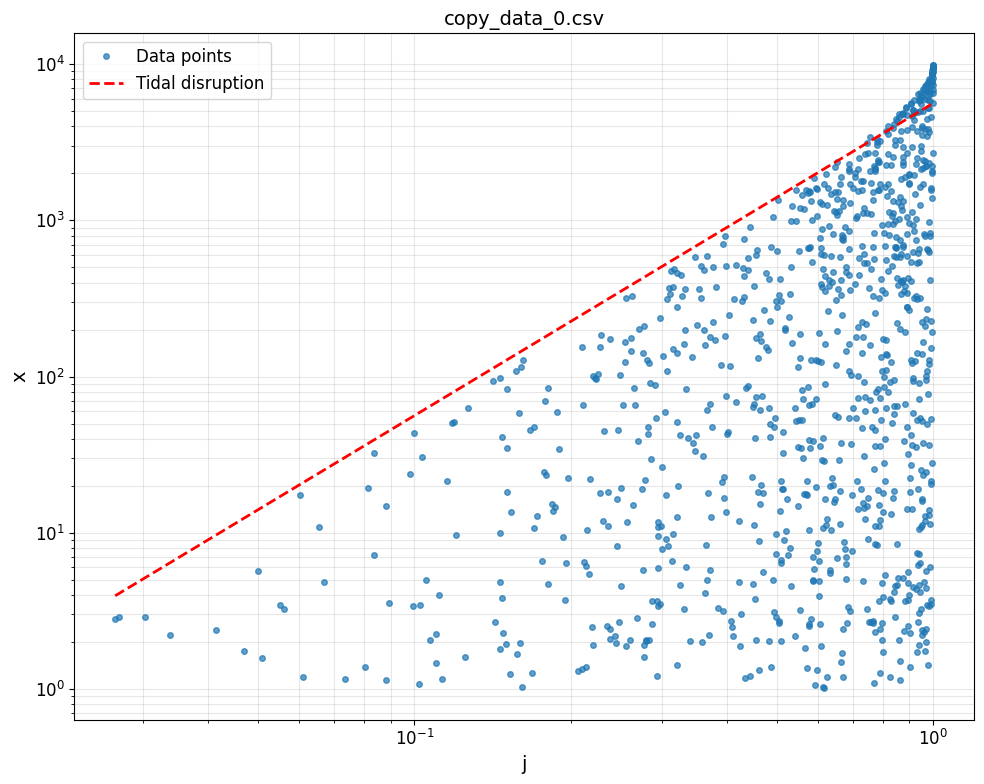

In [3]:
import pandas as pd
plt.figure(figsize=(10, 8))
i=0
df = pd.read_csv(f"data/runtime/copy_data_{i}.csv")

plt.loglog(df['jvalue'], df['xvalue'], 'o', markersize=4, alpha=0.7, label="Data points")
plt.title(f"copy_data_{i}.csv", fontsize=14)

j_values = np.logspace(np.log10(df['jvalue'].min()), np.log10(df['jvalue'].max()), 100)
x_tidal = 10**3.75 * j_values**2
plt.loglog(j_values, x_tidal, 'r--', linewidth=2, label="Tidal disruption")

plt.xlabel("j", fontsize=14)
plt.ylabel("x", fontsize=14)
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="best", fontsize=12)

plt.tight_layout()
plt.show()


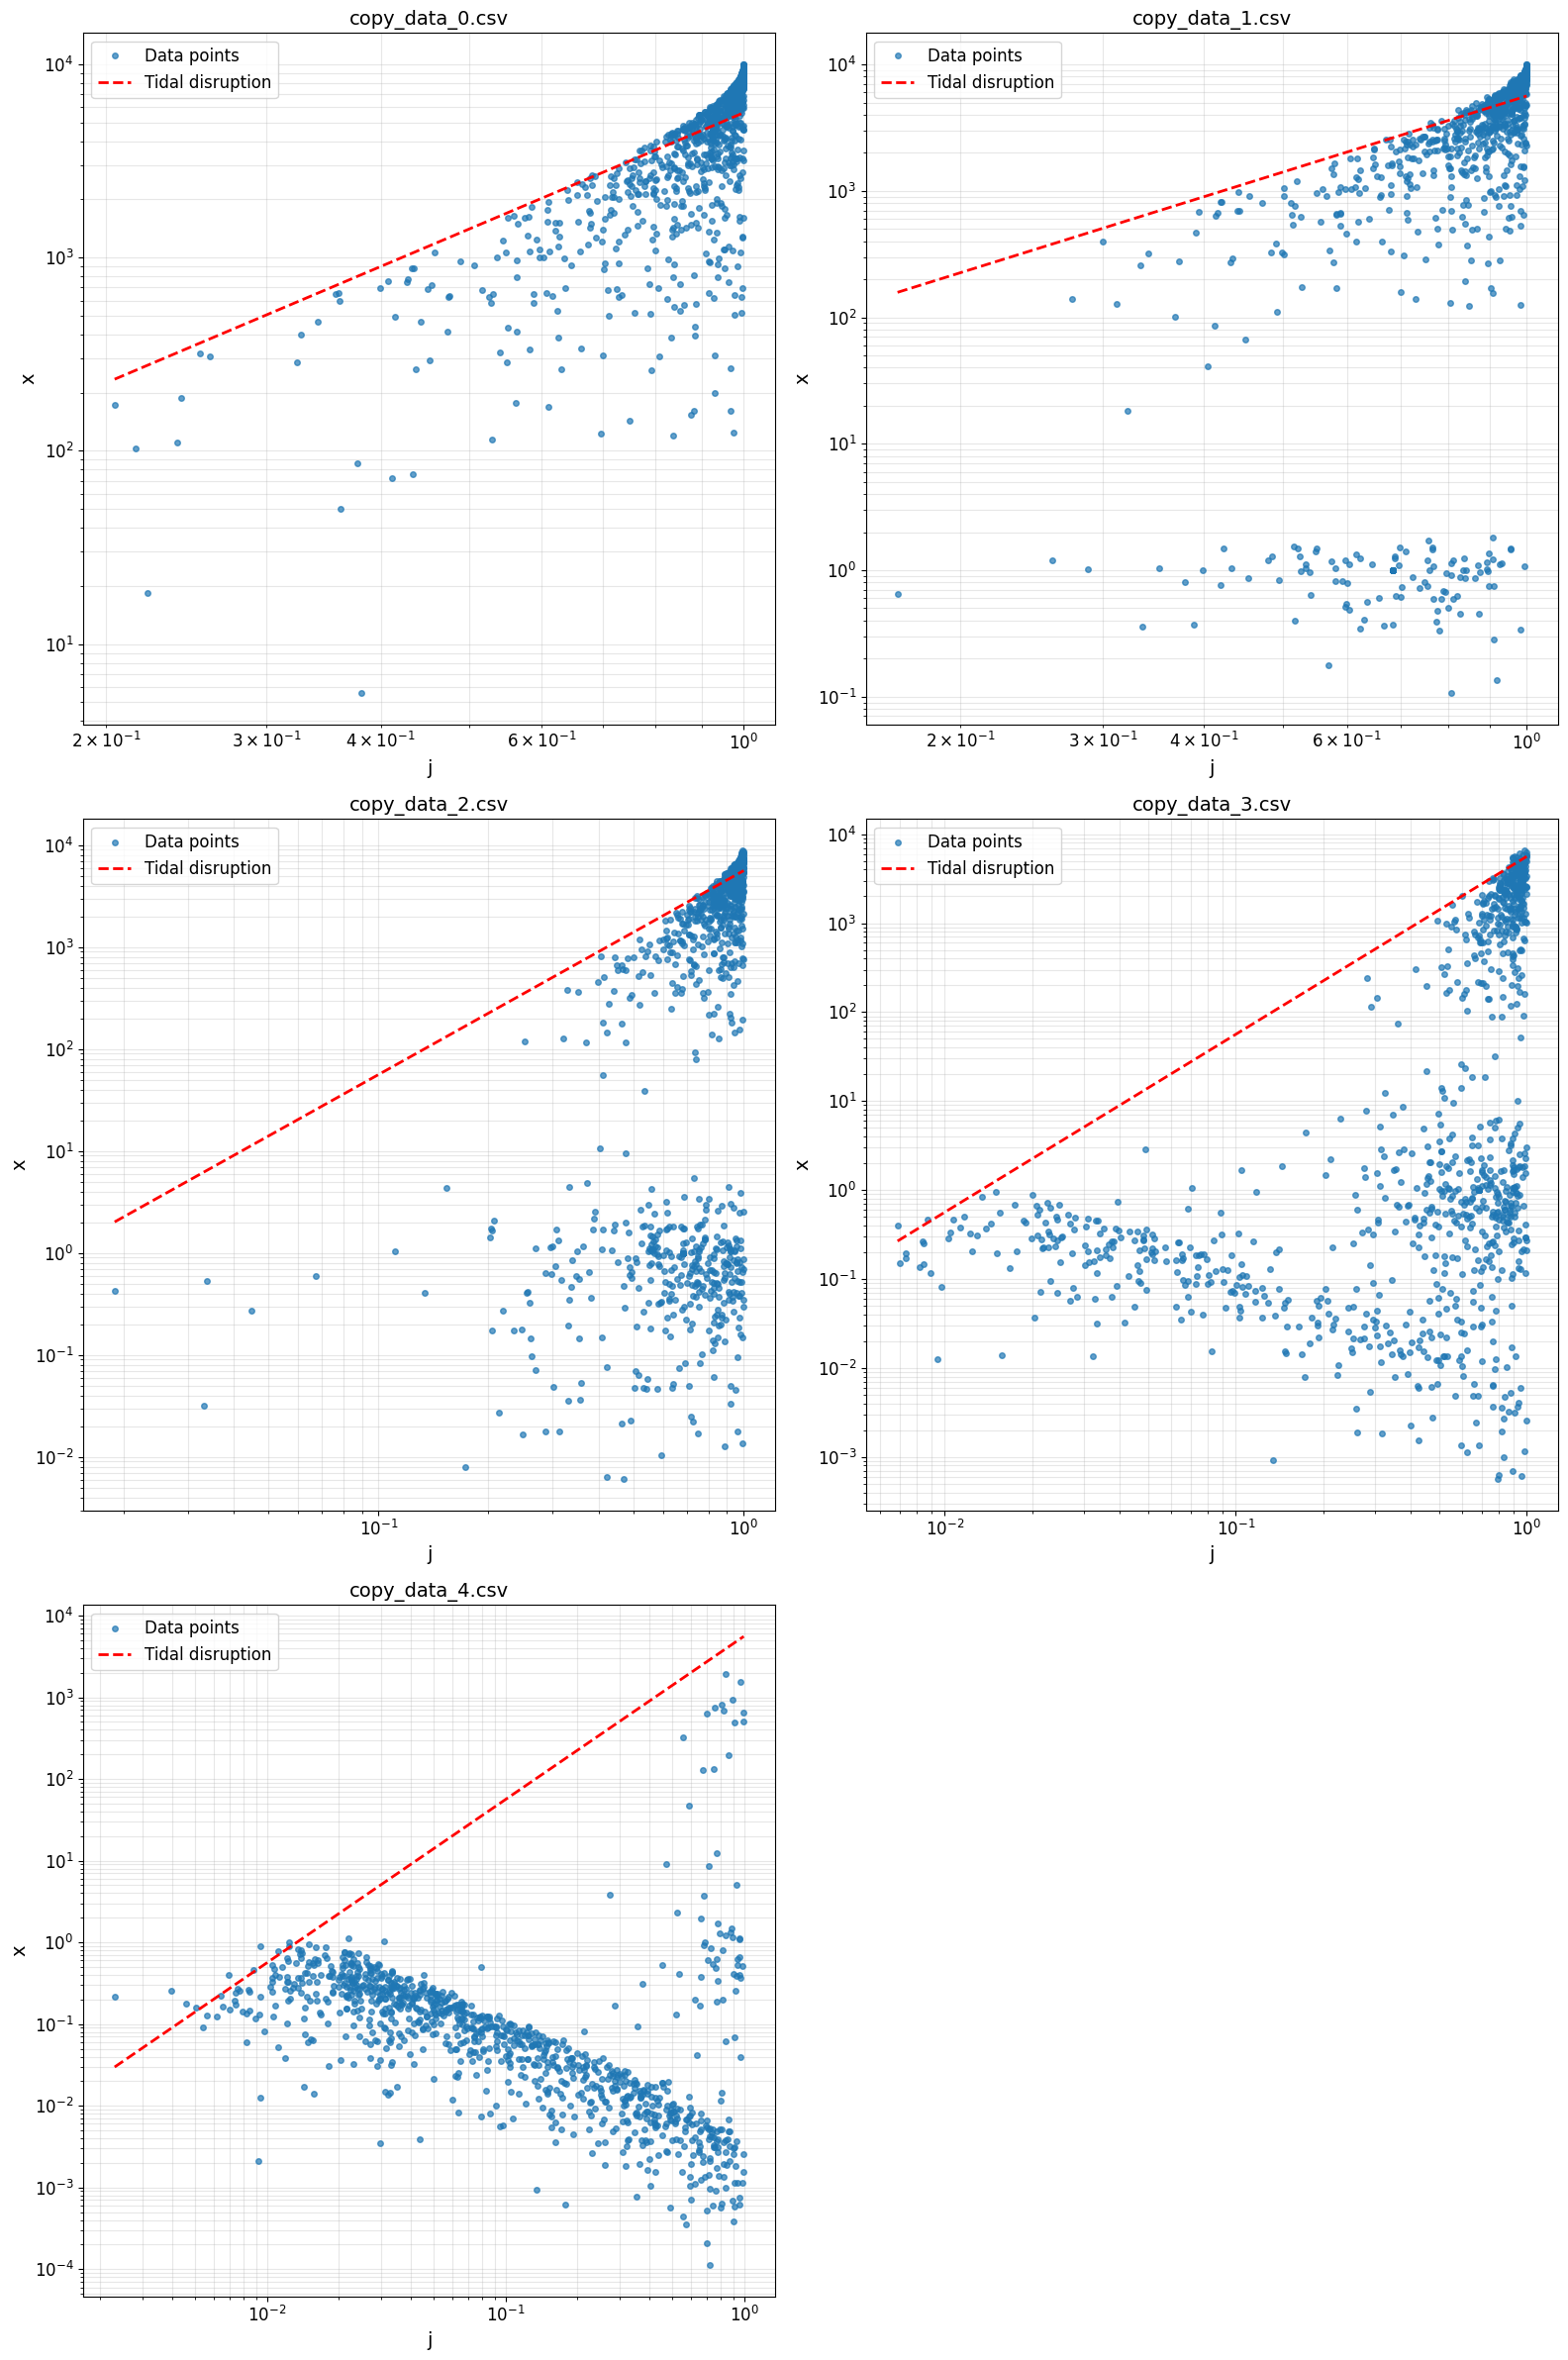

In [4]:
import pandas as pd
plt.figure(figsize=(16, 24))

for i in range(5):
    plt.subplot(3, 2, i+1)
    df = pd.read_csv(f"data/snapshots/archived/annihilation/copy_data_{i}.csv")
    
    plt.loglog(df['jvalue'], df['xvalue'], 'o', markersize=4, alpha=0.7, label="Data points")
    plt.title(f"copy_data_{i}.csv", fontsize=14)
    
    j_values = np.logspace(np.log10(df['jvalue'].min()), np.log10(df['jvalue'].max()), 100)
    x_tidal = 10**3.75 * j_values**2
    plt.loglog(j_values, x_tidal, 'r--', linewidth=2, label="Tidal disruption")
    
    plt.xlabel("j", fontsize=14)
    plt.ylabel("x", fontsize=14)
    plt.grid(True, which="both", alpha=0.3)
    plt.legend(loc="best", fontsize=12)

plt.tight_layout()
plt.show()
